In [1]:
#ACTIVIDAD 

In [2]:
#Librerias 
#Tratamiento de datos
import numpy as np
import pandas as pd
#Gráficos 
import matplotlib.pyplot as plt
#Preprocesado y modelo
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from numpy import linalg as LA

In [4]:
#Carga de la base de datos
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
columnas = ['Sepalo_Largo','Sepalo_Ancho','Petalo_Largo','Petalo_Ancho','Especie']
df_completo = pd.read_csv(url, header=None, names=columnas)
df_completo

,Sepalo_Largo,Sepalo_Ancho,Petalo_Largo,Petalo_Ancho,Especie
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [6]:
#Separar las variables numericas (sin especie)
df = df_completo.drop(columns=['Especie'])
df

,Sepalo_Largo,Sepalo_Ancho,Petalo_Largo,Petalo_Ancho
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [7]:
#numero de renglones de la base de datos 
index = df.index
renglones = len(index)
renglones

150

In [8]:
#Estandarizacion de las variables
df2 = StandardScaler().fit_transform(df)
df2

array([[-9.00681170e-01,  1.03205722e+00, -1.34127240e+00,
        -1.31297673e+00],
       [-1.14301691e+00, -1.24957601e-01, -1.34127240e+00,
        -1.31297673e+00],
       [-1.38535265e+00,  3.37848329e-01, -1.39813811e+00,
        -1.31297673e+00],
       [-1.50652052e+00,  1.06445364e-01, -1.28440670e+00,
        -1.31297673e+00],
       [-1.02184904e+00,  1.26346019e+00, -1.34127240e+00,
        -1.31297673e+00],
       [-5.37177559e-01,  1.95766909e+00, -1.17067529e+00,
        -1.05003079e+00],
       [-1.50652052e+00,  8.00654259e-01, -1.34127240e+00,
        -1.18150376e+00],
       [-1.02184904e+00,  8.00654259e-01, -1.28440670e+00,
        -1.31297673e+00],
       [-1.74885626e+00, -3.56360566e-01, -1.34127240e+00,
        -1.31297673e+00],
       [-1.14301691e+00,  1.06445364e-01, -1.28440670e+00,
        -1.44444970e+00],
       [-5.37177559e-01,  1.49486315e+00, -1.28440670e+00,
        -1.31297673e+00],
       [-1.26418478e+00,  8.00654259e-01, -1.22754100e+00,
      

In [9]:
#Calculo de la matriz de correlaciones para la matriz transformada 
A = (1/renglones) * np.dot(df2.T,df2)
A

array([[ 1.        , -0.10936925,  0.87175416,  0.81795363],
       [-0.10936925,  1.        , -0.4205161 , -0.35654409],
       [ 0.87175416, -0.4205161 ,  1.        ,  0.9627571 ],
       [ 0.81795363, -0.35654409,  0.9627571 ,  1.        ]])

In [10]:
#Entrenamiento del modelo de ACP con el escalado de los datos
pca_pipe = make_pipeline(StandardScaler(),PCA())
pca_pipe.fit(df)
#Se extre el modelo entrendo del pipeline
modelo_pca = pca_pipe.named_steps['pca']
print("Eigenvalores:")
results = LA.eigvals(A)
print(results)

Eigenvalores:
[2.91081808 0.92122093 0.14735328 0.02060771]


In [11]:
#Porcentaje de la varianza explicada por cada nuevo componente
print("Porcentaje de varianza explicada por componente")
print(modelo_pca.explained_variance_ratio_)

Porcentaje de varianza explicada por componente
[0.72770452 0.23030523 0.03683832 0.00515193]


In [20]:
#Varianza acumulada 
print("Porcentaje de varianza acumulada")
print(np.cumsum(modelo_pca.explained_variance_ratio_))       

Porcentaje de varianza acumulada
[0.72770452 0.95800975 0.99484807 1.        ]


In [ ]:
#Al utilizar los primeros dos componentes tenemos un grado de explicacion de la varianza de 95.8%

In [13]:
#Cálculo de los eigenvectores
print("Eigenvectores (por renglón):")
pd.DataFrame(data = modelo_pca.components_,
             columns = df.columns,
             index = ['PC1','PC2','PC3','PC4'])

Eigenvectores (por renglón):


,Sepalo_Largo,Sepalo_Ancho,Petalo_Largo,Petalo_Ancho
PC1,0.522372,-0.263355,0.581254,0.565611
PC2,0.372318,0.925556,0.021095,0.065416
PC3,0.721017,-0.242033,-0.140892,-0.633801
PC4,-0.261996,0.124135,0.801154,-0.523546


In [14]:
#Proyecciones de los componentes 
proyecciones = np.dot(modelo_pca.components_, df2.T)
proyecciones = pd.DataFrame(proyecciones, index = ['PC1','PC2','PC3','PC4'])
proyecciones = proyecciones.transpose().set_index(df.index)
proyecciones

,PC1,PC2,PC3,PC4
0,-2.264542,0.505704,0.121943,-0.023073
1,-2.086426,-0.655405,0.227251,-0.103208
2,-2.367950,-0.318477,-0.051480,-0.027825
3,-2.304197,-0.575368,-0.098860,0.066311
4,-2.388777,0.674767,-0.021428,0.037397
...,...,...,...,...
145,1.870522,0.382822,-0.254532,-0.388890
146,1.558492,-0.905314,0.025382,-0.221322
147,1.520845,0.266795,-0.179277,-0.118903
148,1.376391,1.016362,-0.931405,-0.024146


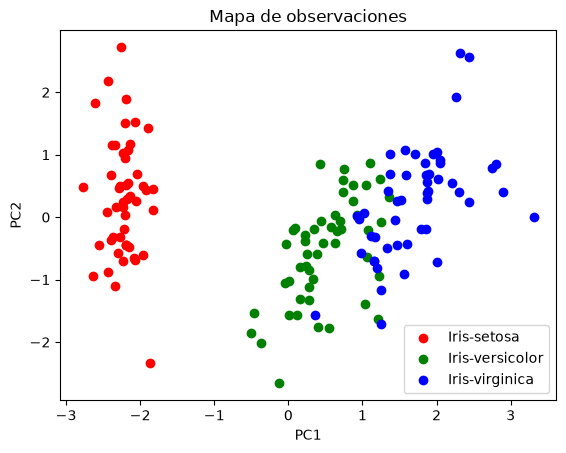

In [17]:
#Mapa de observaciones
especies = df_completo['Especie']
colores_dict = {'Iris-setosa':'red','Iris-versicolor':'green','Iris-virginica':'blue'}

x = proyecciones.iloc[:,0].to_numpy()
y = proyecciones.iloc[:,1].to_numpy()
fig, ax = plt.subplots()
ax.set_title("Mapa de observaciones")
for especie in colores_dict:
    mask = (especies == especie).to_numpy()
    ax.scatter(x[mask], y[mask], c=colores_dict[especie], label=especie)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()

In [16]:
#Mapa de factores
componentes_2 = pd.DataFrame(data = modelo_pca.components_,
                             columns= df.columns,
                             index = ['PC1','PC2','PC3','PC4'])
componentes_2 = componentes_2.iloc[0:2,:]
componentes_2 = componentes_2.T
componentes_2

,PC1,PC2
Sepalo_Largo,0.522372,0.372318
Sepalo_Ancho,-0.263355,0.925556
Petalo_Largo,0.581254,0.021095
Petalo_Ancho,0.565611,0.065416


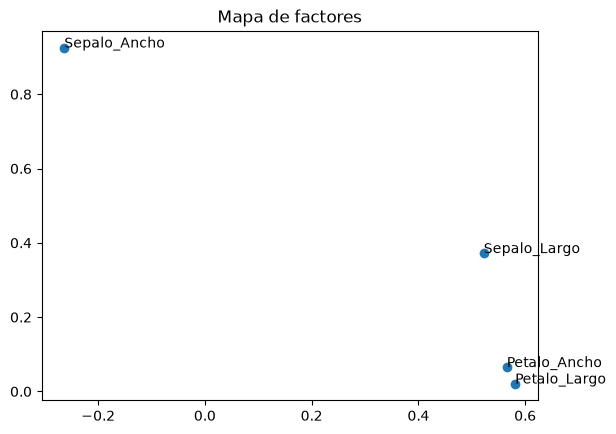

In [18]:
x = componentes_2.iloc[:,0]
y = componentes_2.iloc[:,1]
z = componentes_2.index
x = x.to_numpy()
y = y.to_numpy()
fig, ax = plt.subplots()
ax.set_title("Mapa de factores")
ax.scatter(x,y)
for i, txt in enumerate(z):
    ax.annotate(txt, (x[i], y[i]))

In [ ]:
#Podemos concluir que:
#Iris setosa es de sepalo ancho, iris virginica mayormente es de sepalo largo aunque tambien algunas pueden presentar petalo ancho y largo, al igual que iris versicolor
#Si comparamos la observación 0 y 149, vemos que:
#     #         Sepalo_Largo	Sepalo_Ancho	Petalo_Largo	Petalo_Ancho	Especie
#     0          	5.1          	3.5         	1.4          0.2	Iris-setosa
#    149	        5.9	            3.0	            5.1 	     1.8	Iris-virginica

#vemos que la numero 0 tiene un petalo mucho mas pequeño con un sepalo ancho, comparado con la observacion 149 que es virginica con sepalo largo y es de petalo más largo y ancho 

In [19]:
#Procedimiento para obtener la matriz estandarizada original
original = np.dot(modelo_pca.components_.T, proyecciones.T)
original = original.T
print(original)

[[-9.00681170e-01  1.03205722e+00 -1.34127240e+00 -1.31297673e+00]
 [-1.14301691e+00 -1.24957601e-01 -1.34127240e+00 -1.31297673e+00]
 [-1.38535265e+00  3.37848329e-01 -1.39813811e+00 -1.31297673e+00]
 [-1.50652052e+00  1.06445364e-01 -1.28440670e+00 -1.31297673e+00]
 [-1.02184904e+00  1.26346019e+00 -1.34127240e+00 -1.31297673e+00]
 [-5.37177559e-01  1.95766909e+00 -1.17067529e+00 -1.05003079e+00]
 [-1.50652052e+00  8.00654259e-01 -1.34127240e+00 -1.18150376e+00]
 [-1.02184904e+00  8.00654259e-01 -1.28440670e+00 -1.31297673e+00]
 [-1.74885626e+00 -3.56360566e-01 -1.34127240e+00 -1.31297673e+00]
 [-1.14301691e+00  1.06445364e-01 -1.28440670e+00 -1.44444970e+00]
 [-5.37177559e-01  1.49486315e+00 -1.28440670e+00 -1.31297673e+00]
 [-1.26418478e+00  8.00654259e-01 -1.22754100e+00 -1.31297673e+00]
 [-1.26418478e+00 -1.24957601e-01 -1.34127240e+00 -1.44444970e+00]
 [-1.87002413e+00 -1.24957601e-01 -1.51186952e+00 -1.44444970e+00]
 [-5.25060772e-02  2.18907205e+00 -1.45500381e+00 -1.31297673e